# Aula 11 — Fundamentos de AED e Estatística Descritiva (Teórica) · Exercícios

**Unidade 3 — Análise Exploratória de Dados e Visualização** · ver também: [conteúdo](conteudo.ipynb) · [atividades](atividades.ipynb)

**💻 Exemplo Prático e Exercício — Estatística descritiva na prática (Aula 11)**

O pacote abaixo traz o **exemplo guiado** (`Aula11_AED_Estatistica_Descritiva.ipynb`), com todas as saídas e gráficos: tipos de variáveis, média × mediana × moda, desvio-padrão, CV e IQR, histogramas, assimetria e boxplots, comparação de grupos, correlações de Pearson e Spearman, matriz de correlação, variável de confusão e hipóteses exploratórias, usando 300 estudantes de um curso fictício. Traz também o **exercício prático** (`Aula11_Exercicio_Pratico.ipynb`), mais simples, com 90 dias de vendas de uma sorveteria: nove passos com o resultado esperado em cada um. O exercício é para treino e não precisa ser entregue.

---
## Pacote — Aula 11 (notebooks e datasets)

> Arquivo ZIP com o exemplo guiado (com saídas e gráficos), o exercício prático, os dois datasets sintéticos (estudantes e sorveteria) e o script gerador. Extraia mantendo a pasta dados ao lado dos notebooks.

> Pacote `aula11_pacote_aed.zip` extraído nesta pasta: `Aula11_AED_Estatistica_Descritiva.ipynb`, `LEIA-ME.txt`, `Aula11_Exercicio_Pratico.ipynb`, `gerar_dados.py` e as pastas `dados/`.

## Pacote — Aula 11 (notebooks e datasets) — `Aula11_AED_Estatistica_Descritiva.ipynb`

> Notebook original do professor (cópia intacta ao lado deste arquivo). Rode em ordem; os caminhos `dados/...` são relativos à pasta da aula.

### Aula 11 — Fundamentos de AED e Estatística Descritiva

**Unidade 3 — Análise Exploratória de Dados e Visualização** · Análise e Ciência de Dados (Especialização, IFRN)

Na Unidade 2 aprendemos a **obter** e **limpar** dados. Agora começa a parte de **entender** os dados: a **Análise Exploratória de Dados (AED)**, ou *Exploratory Data Analysis (EDA)*, termo popularizado por John Tukey. A ideia é olhar os dados com resumos numéricos e gráficos simples **antes** de qualquer modelo, para descobrir padrões, problemas e boas perguntas.

**Dados da aula:** `dados/desempenho_estudantes.csv` — 300 estudantes de um curso **fictício**: horas de estudo por semana, horas de sono, tempo de celular por dia, faltas, tempo de deslocamento, mês de nascimento, turno, se trabalha e a nota final (0 a 10). Os dados são **sintéticos** (gerados por `gerar_dados.py` com semente fixa) e foram pensados para ilustrar cada conceito.

**Roteiro:** tipos de variáveis → tendência central → dispersão → distribuições (forma, assimetria, boxplot) → comparação entre grupos → correlação (Pearson e Spearman) → matriz de correlação → cuidados (outliers, causalidade) → hipóteses exploratórias.

> **Instalação:** `pip install pandas numpy matplotlib scipy`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 12)

# cores usadas nos gráficos (verde e âmbar do IFRN; cinza para elementos de apoio)
VERDE, AMBAR, CINZA = "#00693e", "#c6580d", "#8a9299"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e9ec", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})

df = pd.read_csv("dados/desempenho_estudantes.csv")
print(df.shape)
df.head()

(300, 10)


  id_estudante  turno trabalha  horas_estudo_semana  horas_sono  tempo_celular_h  faltas  deslocamento_min  mes_nascimento  \
0         E001  Noite      Sim                  3.2         5.6              6.0       8                29               9   
1         E002  Tarde      Não                  7.2         7.2              2.5       8                40              11   
2         E003  Tarde      Não                  3.1         6.1              4.7       3                31               1   
3         E004  Tarde      Não                  8.4         8.4              4.8       2                33               1   
4         E005  Tarde      Não                  6.1         7.2              3.8       6                24               4   

   nota_final  
0         3.5  
1         6.1  
2         4.6  
3         6.6  
4         5.4  

#### Parte 1 — Que tipo de variável é cada coluna?

O tipo da variável decide quais resumos e gráficos fazem sentido:

| Tipo | Subtipo | Exemplo nos dados | Resumos adequados |
|---|---|---|---|
| **Qualitativa** (categórica) | nominal — sem ordem | `turno`, `trabalha` | frequência, proporção, **moda** |
| | ordinal — com ordem | (ex.: conceito A/B/C) | frequência, moda, **mediana** |
| **Quantitativa** (numérica) | discreta — contagem | `faltas`, `mes_nascimento`* | média, mediana, desvio... |
| | contínua — medida | `horas_sono`, `nota_final` | média, mediana, desvio... |

\* Cuidado: `mes_nascimento` é guardado como número, mas a "média do mês de nascimento" não tem significado útil. **O tipo no Pandas não é o mesmo que o tipo estatístico.**

In [2]:
print(df.dtypes.to_string())
print()
for col in ["turno", "trabalha"]:
    print(col, "→", df[col].value_counts().to_dict(), "| proporção:",
          (df[col].value_counts(normalize=True) * 100).round(1).to_dict())

id_estudante               str
turno                      str
trabalha                   str
horas_estudo_semana    float64
horas_sono             float64
tempo_celular_h        float64
faltas                   int64
deslocamento_min         int64
mes_nascimento           int64
nota_final             float64

turno → {'Manhã': 114, 'Tarde': 102, 'Noite': 84} | proporção: {'Manhã': 38.0, 'Tarde': 34.0, 'Noite': 28.0}
trabalha → {'Não': 202, 'Sim': 98} | proporção: {'Não': 67.3, 'Sim': 32.7}


#### Parte 2 — Medidas de tendência central

Respondem à pergunta **"qual é o valor típico?"**

- **Média** — soma ÷ quantidade. Usa todos os valores, mas é **sensível a valores extremos**.
- **Mediana** — o valor do meio quando os dados estão ordenados (50% abaixo, 50% acima). **Robusta** a extremos.
- **Moda** — o valor mais frequente. A única que serve para variáveis nominais.

In [3]:
resumo = pd.DataFrame({
    "média": df[["nota_final", "horas_sono", "horas_estudo_semana", "deslocamento_min"]].mean(),
    "mediana": df[["nota_final", "horas_sono", "horas_estudo_semana", "deslocamento_min"]].median(),
}).round(2)
resumo["média − mediana"] = (resumo["média"] - resumo["mediana"]).round(2)
print(resumo.to_string())
print()
print("Moda do turno:", df["turno"].mode()[0], "| moda das faltas:", df["faltas"].mode()[0])

                     média  mediana  média − mediana
nota_final            5.69     5.80            -0.11
horas_sono            7.06     7.10            -0.04
horas_estudo_semana   7.34     6.25             1.09
deslocamento_min     26.01    23.00             3.01

Moda do turno: Manhã | moda das faltas: 3


Repare: para `nota_final` e `horas_sono`, média ≈ mediana. Para `horas_estudo_semana` e `deslocamento_min`, a **média é bem maior que a mediana**. Isso acontece quando há uma **cauda à direita**: poucos estudantes estudam muito (até 34 h/semana) ou moram longe, e esses valores "puxam" a média para cima. Nesses casos, a mediana descreve melhor o estudante típico.

##### Experimento: o efeito de um único valor extremo

In [4]:
horas = df["horas_estudo_semana"].copy()
com_extremo = pd.concat([horas, pd.Series([150.0])], ignore_index=True)   # um erro de digitação: 150 h/semana
print(f"Sem o extremo → média {horas.mean():.2f} | mediana {horas.median():.2f}")
print(f"Com o extremo → média {com_extremo.mean():.2f} | mediana {com_extremo.median():.2f}")

Sem o extremo → média 7.34 | mediana 6.25
Com o extremo → média 7.81 | mediana 6.30


Um único valor errado mudou a média em quase meia hora; a mediana praticamente não se moveu. É por isso que a Aula 09 recomendava a mediana para imputar valores ausentes.

#### Parte 3 — Medidas de dispersão

Duas turmas podem ter a mesma média e ser muito diferentes. A **dispersão** mede **o quanto os valores se espalham**:

| Medida | Fórmula / ideia | Observação |
|---|---|---|
| Amplitude | máximo − mínimo | depende só de 2 valores (frágil) |
| Variância | média dos quadrados dos desvios em relação à média | unidade ao quadrado (h²) |
| **Desvio-padrão** | √variância | mesma unidade dos dados |
| **Coeficiente de variação (CV)** | desvio ÷ média × 100% | sem unidade: compara variáveis diferentes |
| **Intervalo interquartil (IQR)** | Q3 − Q1 | faixa dos 50% centrais; robusto a extremos |

> O Pandas calcula a variância e o desvio **amostrais** (divide por *n − 1*), que é o padrão quando os dados são uma amostra.

In [5]:
def dispersao(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({"mín": s.min(), "máx": s.max(), "amplitude": s.max() - s.min(),
                      "variância": s.var(), "desvio": s.std(), "CV (%)": s.std() / s.mean() * 100,
                      "Q1": q1, "Q3": q3, "IQR": q3 - q1})

cols = ["nota_final", "horas_sono", "horas_estudo_semana", "tempo_celular_h", "faltas"]
df[cols].apply(dispersao).T.round(2)

                     mín   máx  amplitude  variância  desvio  CV (%)   Q1    Q3   IQR
nota_final           1.5   9.6        8.1       1.84    1.36   23.83  4.7  6.60  1.90
horas_sono           5.1   9.4        4.3       0.74    0.86   12.15  6.4  7.60  1.20
horas_estudo_semana  0.4  34.2       33.8      25.43    5.04   68.74  3.8  9.60  5.80
tempo_celular_h      0.5   8.9        8.4       1.92    1.39   32.95  3.3  5.12  1.83
faltas               0.0  11.0       11.0       5.32    2.31   54.37  2.0  6.00  4.00

**Leitura:** o sono varia pouco (CV ≈ 12%: quase todos dormem entre 6 e 8 h), enquanto as horas de estudo variam muito (CV ≈ 69%). O CV permite essa comparação mesmo entre variáveis com unidades e escalas diferentes.

##### `describe()` — o resumo de cinco números e mais

Os **cinco números** de Tukey são mínimo, Q1, mediana, Q3 e máximo. O `describe()` traz esses valores, a contagem, a média e o desvio.

In [6]:
df.describe().round(2).T

                     count   mean    std  min   25%    50%    75%   max
horas_estudo_semana  300.0   7.34   5.04  0.4   3.8   6.25   9.60  34.2
horas_sono           300.0   7.06   0.86  5.1   6.4   7.10   7.60   9.4
tempo_celular_h      300.0   4.21   1.39  0.5   3.3   4.20   5.12   8.9
faltas               300.0   4.24   2.31  0.0   2.0   4.00   6.00  11.0
deslocamento_min     300.0  26.01  14.13  5.0  15.0  23.00  33.00  75.0
mes_nascimento       300.0   6.54   3.48  1.0   3.0   7.00  10.00  12.0
nota_final           300.0   5.69   1.36  1.5   4.7   5.80   6.60   9.6

#### Parte 4 — Distribuições: a forma dos dados

Resumos numéricos não mostram tudo. A **distribuição** — como os valores se espalham ao longo da escala — é vista com **histogramas** e **boxplots**:

- **Simétrica** — média ≈ mediana; a assimetria (*skewness*) fica perto de 0.
- **Assimétrica à direita** (positiva) — cauda longa para valores altos; média > mediana; skew > 0.
- **Assimétrica à esquerda** (negativa) — cauda para valores baixos; média < mediana; skew < 0.

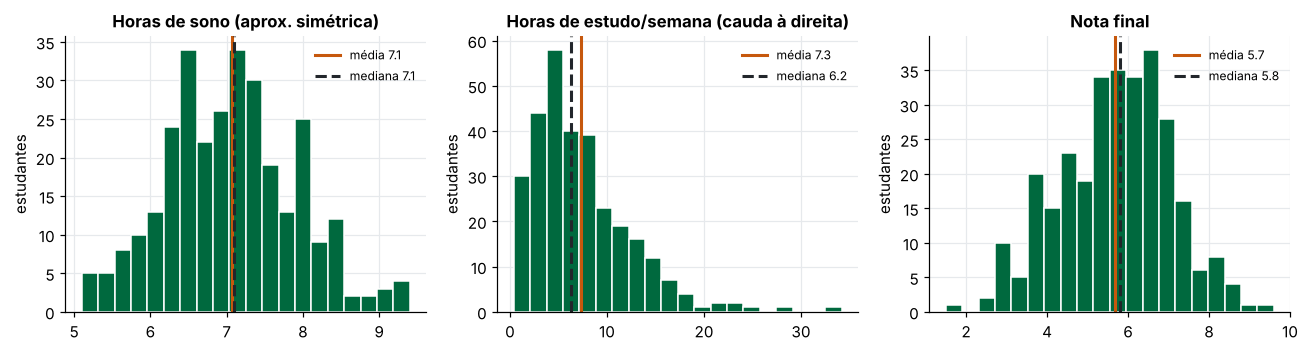

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, col, titulo in zip(eixos, ["horas_sono", "horas_estudo_semana", "nota_final"],
                           ["Horas de sono (aprox. simétrica)", "Horas de estudo/semana (cauda à direita)", "Nota final"]):
    s = df[col]
    ax.hist(s, bins=20, color=VERDE, edgecolor="white", linewidth=1)
    ax.axvline(s.mean(), color=AMBAR, linewidth=2, label=f"média {s.mean():.1f}")
    ax.axvline(s.median(), color="#22262b", linewidth=2, linestyle="--", label=f"mediana {s.median():.1f}")
    ax.set_title(titulo)
    ax.set_ylabel("estudantes")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
forma = pd.DataFrame({"assimetria (skew)": df[cols + ["deslocamento_min"]].skew(),
                      "curtose": df[cols + ["deslocamento_min"]].kurt()}).round(2)
forma

                     assimetria (skew)  curtose
nota_final                       -0.16    -0.17
horas_sono                        0.20    -0.21
horas_estudo_semana               1.51     3.56
tempo_celular_h                   0.06     0.08
faltas                            0.50    -0.19
deslocamento_min                  1.07     1.00

**Curtose** (no Pandas, *excesso* de curtose) compara as caudas com as de uma distribuição normal: perto de 0 → caudas "normais"; positiva → caudas mais pesadas (mais valores extremos). As horas de estudo têm assimetria 1,5 e curtose alta: muitos estudantes estudam pouco e poucos estudam muito.

##### A distribuição normal e a regra 68–95–99,7

Quando a distribuição é aproximadamente **normal** (forma de sino), cerca de **68%** dos valores ficam a 1 desvio-padrão da média, **95%** a 2 desvios e **99,7%** a 3 desvios. As horas de sono são aproximadamente normais — vamos conferir:

In [9]:
s = df["horas_sono"]
m, d = s.mean(), s.std()
for kk in [1, 2, 3]:
    dentro = ((s >= m - kk * d) & (s <= m + kk * d)).mean() * 100
    print(f"±{kk} desvio(s): [{m - kk*d:.2f}, {m + kk*d:.2f}] h → {dentro:.1f}% dos estudantes")

±1 desvio(s): [6.21, 7.92] h → 64.7% dos estudantes
±2 desvio(s): [5.35, 8.78] h → 95.3% dos estudantes
±3 desvio(s): [4.49, 9.64] h → 100.0% dos estudantes


Os percentuais observados (64,7%, 95,3% e 100%) ficam próximos do previsto pela regra. Para as horas de estudo, muito assimétricas, a regra **não** se aplica bem — por isso olhe sempre a forma antes de usar média ± desvio para descrever os dados.

##### Boxplot

O boxplot desenha os cinco números: a caixa vai de Q1 a Q3 (o IQR), a linha interna é a mediana, os "bigodes" vão até o último valor dentro de 1,5·IQR, e os pontos além disso são **candidatos a outlier** (Aula 09). Ele é ótimo para **comparar grupos**:

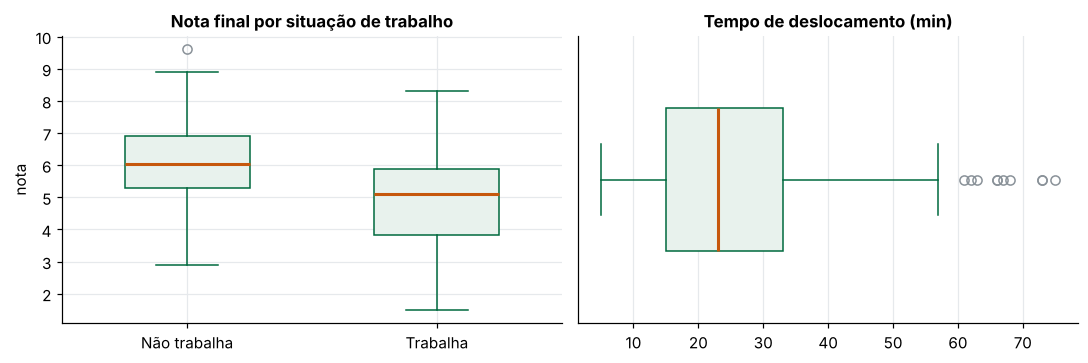

In [10]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.4))
grupos = [df.loc[df["trabalha"] == g, "nota_final"] for g in ["Não", "Sim"]]
eixos[0].boxplot(grupos, tick_labels=["Não trabalha", "Trabalha"], widths=0.5, patch_artist=True,
                 boxprops=dict(facecolor="#e8f2ed", color=VERDE), medianprops=dict(color=AMBAR, linewidth=2),
                 whiskerprops=dict(color=VERDE), capprops=dict(color=VERDE), flierprops=dict(markeredgecolor=CINZA))
eixos[0].set_title("Nota final por situação de trabalho")
eixos[0].set_ylabel("nota")
eixos[1].boxplot(df["deslocamento_min"], vert=False, widths=0.5, patch_artist=True,
                 boxprops=dict(facecolor="#e8f2ed", color=VERDE), medianprops=dict(color=AMBAR, linewidth=2),
                 whiskerprops=dict(color=VERDE), capprops=dict(color=VERDE), flierprops=dict(markeredgecolor=CINZA))
eixos[1].set_title("Tempo de deslocamento (min)")
eixos[1].set_yticks([])
plt.tight_layout()
plt.show()

#### Parte 5 — Comparando grupos

`groupby` + `agg` calcula as medidas para cada grupo. Comparar média **e** mediana (e o desvio) evita conclusões apressadas.

In [11]:
(df.groupby("trabalha")[["horas_estudo_semana", "horas_sono", "faltas", "nota_final"]]
   .agg(["mean", "median"]).round(2))

         horas_estudo_semana        horas_sono        faltas        nota_final       
                        mean median       mean median   mean median       mean median
trabalha                                                                             
Não                     8.35    7.2       7.23    7.2   3.42    3.0       6.05   6.05
Sim                     5.25    4.1       6.73    6.6   5.94    6.0       4.94   5.10

In [12]:
df.groupby("turno")["nota_final"].agg(["count", "mean", "median", "std"]).round(2).reindex(["Manhã", "Tarde", "Noite"])

       count  mean  median   std
turno                           
Manhã    114  5.87    6.00  1.25
Tarde    102  5.79    5.80  1.29
Noite     84  5.32    5.55  1.51

Quem trabalha estuda cerca de 3 h a menos por semana, dorme meia hora a menos, falta mais e tem nota mediana menor. O turno da noite tem nota média menor — mas o turno da noite também concentra quem trabalha. **Será o turno ou o trabalho?** Guarde essa pergunta para a Parte 8.

#### Parte 6 — Correlação: duas variáveis andam juntas?

O **gráfico de dispersão** (*scatter plot*) é o primeiro passo. A **correlação** resume, num número entre −1 e +1, a força e a direção da associação:

| Coeficiente | Mede | Como calcula | Bom para |
|---|---|---|---|
| **Pearson (r)** | associação **linear** | covariância ÷ (desvio_x · desvio_y) | relações em linha reta, sem outliers fortes |
| **Spearman (ρ)** | associação **monotônica** (sempre cresce ou sempre decresce) | Pearson aplicado aos **postos** (rankings) | relações curvas, dados ordinais, presença de outliers |

Guia de leitura (aproximado): |r| < 0,1 desprezível · 0,1–0,3 fraca · 0,3–0,5 moderada · 0,5–0,7 forte · > 0,7 muito forte. O **sinal** indica a direção: + (as duas sobem juntas) ou − (uma sobe e a outra desce).

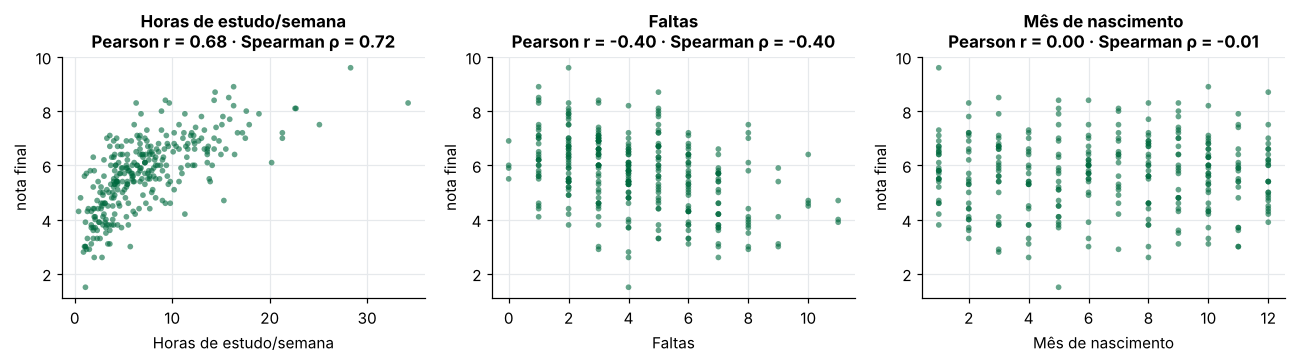

In [13]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.4))
pares = [("horas_estudo_semana", "Horas de estudo/semana"), ("faltas", "Faltas"), ("mes_nascimento", "Mês de nascimento")]
for ax, (col, rotulo) in zip(eixos, pares):
    ax.scatter(df[col], df["nota_final"], s=14, color=VERDE, alpha=0.6, edgecolors="none")
    r = round(df[col].corr(df["nota_final"]), 2) + 0.0          # + 0.0 evita exibir "-0.00"
    rho = round(df[col].corr(df["nota_final"], method="spearman"), 2) + 0.0
    ax.set_title(f"{rotulo}\nPearson r = {r:.2f} · Spearman ρ = {rho:.2f}")
    ax.set_xlabel(rotulo)
    ax.set_ylabel("nota final")
plt.tight_layout()
plt.show()

- **Estudo × nota:** associação positiva forte. Repare que a nuvem **curva**: as primeiras horas de estudo ajudam muito, e as seguintes cada vez menos (efeito de saturação). Como a relação é monotônica, mas não linear, o **Spearman (0,72) fica acima do Pearson (0,68)**.
- **Faltas × nota:** associação negativa moderada.
- **Mês de nascimento × nota:** correlação ≈ 0 — não há relação (como esperado).

##### Calculando com Pandas e SciPy

`Series.corr()` dá o coeficiente; `scipy.stats.pearsonr` e `spearmanr` dão também o **p-valor**, que indica se uma correlação desse tamanho seria improvável se, na população, não houvesse associação. (Testes de hipóteses serão aprofundados mais adiante; por ora, use o p-valor só como um indicativo.)

In [14]:
for col in ["horas_estudo_semana", "horas_sono", "tempo_celular_h", "faltas", "deslocamento_min", "mes_nascimento"]:
    r, p_r = stats.pearsonr(df[col], df["nota_final"])
    rho, p_s = stats.spearmanr(df[col], df["nota_final"])
    print(f"{col:22s} Pearson r = {r:+.2f} (p = {p_r:.3f})   Spearman ρ = {rho:+.2f} (p = {p_s:.3f})")

horas_estudo_semana    Pearson r = +0.68 (p = 0.000)   Spearman ρ = +0.72 (p = 0.000)
horas_sono             Pearson r = +0.24 (p = 0.000)   Spearman ρ = +0.23 (p = 0.000)
tempo_celular_h        Pearson r = -0.27 (p = 0.000)   Spearman ρ = -0.25 (p = 0.000)
faltas                 Pearson r = -0.40 (p = 0.000)   Spearman ρ = -0.40 (p = 0.000)
deslocamento_min       Pearson r = -0.08 (p = 0.154)   Spearman ρ = -0.08 (p = 0.182)
mes_nascimento         Pearson r = -0.00 (p = 0.977)   Spearman ρ = -0.01 (p = 0.904)


##### Pearson × Spearman com um outlier

Vamos ver como um único ponto extremo afeta cada coeficiente. O tempo de celular tem correlação negativa fraca com a nota. Suponha que **um registro** tenha sido digitado errado: um estudante com nota 9,5 e "36 h de celular por dia" (o correto era 3,6 h).

In [15]:
x = pd.concat([df["tempo_celular_h"], pd.Series([36.0])], ignore_index=True)
y = pd.concat([df["nota_final"], pd.Series([9.5])], ignore_index=True)
print(f"Sem o outlier → Pearson {df['tempo_celular_h'].corr(df['nota_final']):.2f} | "
      f"Spearman {df['tempo_celular_h'].corr(df['nota_final'], method='spearman'):.2f}")
print(f"Com o outlier → Pearson {x.corr(y):.2f} | Spearman {x.corr(y, method='spearman'):.2f}")

Sem o outlier → Pearson -0.27 | Spearman -0.25
Com o outlier → Pearson -0.03 | Spearman -0.24


Um único ponto (entre 301) praticamente **apagou** a correlação de Pearson (de −0,27 para perto de zero); o Spearman mudou pouco, porque trabalha com postos: o outlier vira apenas "o maior valor". **Sempre olhe o gráfico de dispersão antes de confiar no coeficiente** — e trate os erros antes (Aula 09).

#### Parte 7 — Matriz de correlação

Com muitas variáveis numéricas, `df.corr()` calcula todas as correlações par a par. Um **mapa de calor** (*heatmap*) com escala divergente (âmbar para negativo, cinza claro no zero, verde para positivo) facilita a leitura.

In [16]:
numericas = ["horas_estudo_semana", "horas_sono", "tempo_celular_h", "faltas",
             "deslocamento_min", "mes_nascimento", "nota_final"]
matriz = df[numericas].corr(method="spearman").round(2)
matriz

                     horas_estudo_semana  horas_sono  tempo_celular_h  faltas  deslocamento_min  mes_nascimento  nota_final
horas_estudo_semana                 1.00       -0.04            -0.02   -0.21             -0.09           -0.03        0.72
horas_sono                         -0.04        1.00            -0.15   -0.09             -0.00           -0.06        0.23
tempo_celular_h                    -0.02       -0.15             1.00    0.10             -0.11           -0.06       -0.25
faltas                             -0.21       -0.09             0.10    1.00              0.08            0.04       -0.40
deslocamento_min                   -0.09       -0.00            -0.11    0.08              1.00            0.03       -0.08
mes_nascimento                     -0.03       -0.06            -0.06    0.04              0.03            1.00       -0.01
nota_final                          0.72        0.23            -0.25   -0.40             -0.08           -0.01        1.00

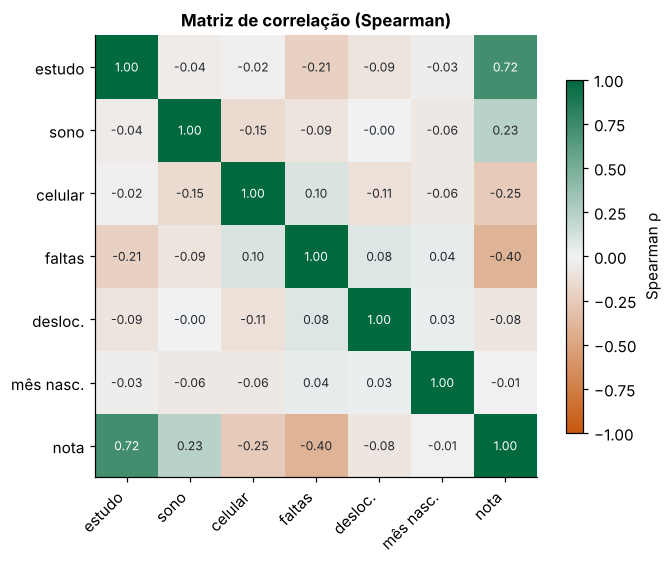

In [17]:
from matplotlib.colors import LinearSegmentedColormap
divergente = LinearSegmentedColormap.from_list("ambar_verde", [AMBAR, "#f1f2f3", VERDE])

rotulos = ["estudo", "sono", "celular", "faltas", "desloc.", "mês nasc.", "nota"]
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(matriz.values, cmap=divergente, vmin=-1, vmax=1)
ax.set_xticks(range(len(rotulos)), rotulos, rotation=45, ha="right")
ax.set_yticks(range(len(rotulos)), rotulos)
ax.grid(False)
for i in range(len(rotulos)):
    for j in range(len(rotulos)):
        v = matriz.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "#22262b")
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Matriz de correlação (Spearman)")
plt.tight_layout()
plt.show()

In [18]:
# os pares mais fortes (sem a diagonal e sem repetir pares)
pares = (matriz.where(np.triu(np.ones(matriz.shape, dtype=bool), k=1))
               .stack().rename("rho").reset_index()
               .rename(columns={"level_0": "variável 1", "level_1": "variável 2"}))
pares["|rho|"] = pares["rho"].abs()
print(pares.sort_values("|rho|", ascending=False).head(6).drop(columns="|rho|").to_string(index=False))

         variável 1      variável 2   rho
horas_estudo_semana      nota_final  0.72
             faltas      nota_final -0.40
    tempo_celular_h      nota_final -0.25
         horas_sono      nota_final  0.23
horas_estudo_semana          faltas -0.21
         horas_sono tempo_celular_h -0.15


**Como ler a matriz:** ela é simétrica (estudo × nota = nota × estudo) e a diagonal vale sempre 1. Procure (1) as correlações mais fortes com a variável de interesse (nota), (2) variáveis explicativas muito correlacionadas entre si (redundância) e (3) variáveis sem relação com nada (mês de nascimento).

#### Parte 8 — Correlação não é causalidade

Uma correlação mostra que duas variáveis **variam juntas** — não que uma **causa** a outra. Três explicações comuns para uma correlação:

1. **Causa direta** — estudar mais melhora a nota (plausível);
2. **Variável de confusão** (*confounder*) — uma terceira variável afeta as duas;
3. **Acaso ou coincidência** — com muitas variáveis, alguma correlação aparece por sorte.

Lembra da pergunta da Parte 5? O turno da noite tem notas menores. Vamos separar por trabalho:

In [19]:
tab = df.pivot_table(index="turno", columns="trabalha", values="nota_final", aggfunc="mean").round(2)
tab["n (trabalha)"] = df[df["trabalha"] == "Sim"].groupby("turno").size()
tab["n (não trabalha)"] = df[df["trabalha"] == "Não"].groupby("turno").size()
tab.reindex(["Manhã", "Tarde", "Noite"])

trabalha   Não   Sim  n (trabalha)  n (não trabalha)
turno                                               
Manhã     5.99  4.93            13               101
Tarde     6.05  4.72            20                82
Noite     6.36  5.01            65                19

Dentro de cada grupo (quem trabalha / quem não trabalha), as notas dos três turnos ficam parecidas — entre quem não trabalha, a noite fica até um pouco acima. A diferença "do turno" vem, em boa parte, de o turno da noite ter muito mais estudantes que trabalham: **trabalhar** é a variável de confusão. (Nestes dados sintéticos sabemos disso porque o gerador foi escrito assim; em dados reais, a AED sugere, mas não prova.)

#### Parte 9 — Formulando hipóteses exploratórias

A AED termina com **perguntas melhores**. Uma **hipótese exploratória** é uma afirmação **testável**, sugerida pelos dados, que orienta as próximas análises. Uma boa hipótese:

- é **específica** (quais variáveis? qual direção?);
- é **mensurável** com os dados disponíveis;
- indica **como seria verificada** (comparação de grupos, correlação, teste, modelo).

| # | Hipótese exploratória | Evidência descritiva | Próximo passo |
|---|---|---|---|
| H1 | Mais horas de estudo estão associadas a notas maiores, com ganho decrescente | ρ = 0,72; nuvem curva | modelo com log(horas) |
| H2 | Estudantes que trabalham têm nota menor, em parte por estudarem e dormirem menos | diferença de ≈1 ponto; menos estudo e sono | comparar grupos controlando estudo/sono |
| H3 | O efeito do turno desaparece quando se considera o trabalho | notas parecidas dentro de cada grupo | análise estratificada / modelo |
| H4 | Mais faltas estão associadas a notas menores | ρ = −0,40 | política de acompanhamento de faltas |

Vamos fechar com uma verificação descritiva da H1 por faixas de estudo:

In [20]:
faixas = pd.cut(df["horas_estudo_semana"], bins=[0, 3, 6, 10, 15, 40],
                labels=["até 3 h", "3–6 h", "6–10 h", "10–15 h", "mais de 15 h"])
df.groupby(faixas, observed=True)["nota_final"].agg(["count", "median", "mean"]).round(2)

                     count  median  mean
horas_estudo_semana                     
até 3 h                 55     4.1  4.15
3–6 h                   91     5.4  5.25
6–10 h                  83     6.1  6.12
10–15 h                 48     6.7  6.65
mais de 15 h            23     7.5  7.52

A nota mediana sobe a cada faixa, mas o ganho diminui nas faixas mais altas — coerente com H1. **Isso é evidência exploratória, não prova**: as próximas aulas (visualização e análise) e a Unidade 4 (modelos) permitem investigar essas hipóteses com mais rigor.

#### Resumo

| Pergunta | Ferramenta |
|---|---|
| Qual o valor típico? | média, mediana (`median`), moda (`mode`) |
| Quanto varia? | desvio (`std`), variância (`var`), CV, IQR (`quantile`) |
| Qual a forma? | histograma, boxplot, `skew`, `kurt` |
| Os grupos diferem? | `groupby().agg()`, boxplot por grupo |
| Duas variáveis andam juntas? | dispersão, `corr()` (Pearson), `corr(method="spearman")` |
| Visão geral das associações | matriz de correlação + heatmap |
| E agora? | hipóteses exploratórias específicas e testáveis |

**Próximo passo:** praticar com o exercício `Aula11_Exercicio_Pratico.ipynb` (vendas de uma sorveteria).

## Pacote — Aula 11 (notebooks e datasets) — `Aula11_Exercicio_Pratico.ipynb`

> Notebook original do professor (cópia intacta ao lado deste arquivo). Rode em ordem; os caminhos `dados/...` são relativos à pasta da aula.

### Exercício Prático — Aula 11: o verão da sorveteria

**Análise e Ciência de Dados** (Especialização, IFRN) — Unidade 3, Aula 11

Este exercício é **para praticar** — não precisa ser entregue. A avaliação da aula é o **formulário avaliativo** no Moodle (prazo **10/11/2026**), e várias questões usam exatamente as situações deste exercício.

**Dados:** `dados/sorveteria.csv` — 90 dias de verão de uma sorveteria **fictícia** (dados sintéticos): data, dia da semana, se é fim de semana, temperatura máxima (°C), chuva (mm), sorvetes vendidos e cafés vendidos.

Em cada passo há um bloco **"Para conferir"** com o resultado esperado. Use o notebook `Aula11_AED_Estatistica_Descritiva.ipynb` como referência.

#### Passo 1 — Carregar e classificar as variáveis

Carregue o arquivo, veja `shape` e `head()` e classifique cada coluna: qualitativa (nominal/ordinal) ou quantitativa (discreta/contínua).

> **Para conferir:** 90 linhas × 7 colunas. `dia_semana` e `fim_de_semana` são qualitativas nominais; `sorvetes_vendidos` e `cafes_vendidos` são quantitativas discretas (contagens); `temperatura_max` e `chuva_mm` são quantitativas contínuas.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

s = pd.read_csv("dados/sorveteria.csv")
# TODO: shape e head()


#### Passo 2 — Tendência central

Calcule média e mediana de `sorvetes_vendidos` e `temperatura_max`. Depois descubra o dia de **maior** venda: o que aconteceu?

> **Para conferir:** sorvetes → média 177,6 e mediana 174,5; temperatura → média 26,9 °C e mediana 27,2 °C. O maior valor é **1.150 sorvetes** em 14/02/2026 — muito acima de todos os outros dias (o segundo maior é 317). Foi um sábado de festival na praça — e um dia relativamente fresco (21,8 °C).

In [ ]:
# TODO: mean() e median(); idxmax() ou sort_values() para achar o dia de maior venda


#### Passo 3 — Sem o dia atípico

Crie `s2` sem o dia do festival e recalcule média e mediana dos sorvetes. Qual medida mudou mais?

> **Para conferir:** sem o festival → média 166,7 e mediana 174,0. A **média** caiu cerca de 11 sorvetes; a mediana, só 0,5.

In [ ]:
# TODO: s2 = s[s["sorvetes_vendidos"] < 1000]


#### Passo 4 — Dispersão

Para `temperatura_max` e `sorvetes_vendidos` (use `s2`), calcule desvio-padrão, coeficiente de variação (CV) e IQR.

> **Para conferir:** temperatura → desvio 3,2 °C, CV 12%, IQR 4,6 °C; sorvetes → desvio 68,5, CV 41%, IQR 102,0. As vendas variam muito mais (em termos relativos) que a temperatura.

In [ ]:
# TODO: std(), std()/mean()*100 e quantile(0.75) - quantile(0.25)


#### Passo 5 — Forma da distribuição

Faça o histograma de `chuva_mm` e calcule a assimetria (`skew`) de `chuva_mm` e `temperatura_max`. Quantos dias **não** choveu?

> **Para conferir:** 67 dos 90 dias sem chuva; a chuva é fortemente assimétrica à direita (skew ≈ 2,3) — por isso média (3,3 mm) é muito maior que a mediana (0 mm). A temperatura é quase simétrica (skew ≈ −0,1).

In [ ]:
# TODO: plt.hist(...), skew(), (s["chuva_mm"] == 0).sum()


#### Passo 6 — Fim de semana vende mais?

Compare média e mediana de sorvetes entre fins de semana e dias úteis (use `s2`).

> **Para conferir:** fim de semana (24 dias) → média 204,6 e mediana 202,0; dias úteis (65 dias) → média 152,7 e mediana 160,0. Nos fins de semana vendem-se cerca de 50 sorvetes a mais.

In [ ]:
# TODO: groupby("fim_de_semana")["sorvetes_vendidos"].agg(["count", "mean", "median"])


#### Passo 7 — Correlação: temperatura × sorvetes

1. Calcule Pearson e Spearman entre `temperatura_max` e `sorvetes_vendidos` **com todos os dias** (`s`).
2. Repita **sem o festival** (`s2`).
3. Faça o gráfico de dispersão de `s`. Por que os dois coeficientes discordam tanto?

> **Para conferir:** com todos os dias → Pearson 0,32 e Spearman 0,80; sem o festival → Pearson 0,85 e Spearman 0,86. Um único ponto extremo derrubou o Pearson; o Spearman, baseado em postos, quase não foi afetado.

In [ ]:
# TODO: corr() e corr(method="spearman") em s e em s2; plt.scatter(...)


#### Passo 8 — Matriz de correlação

Calcule a matriz de Spearman de `temperatura_max`, `chuva_mm`, `sorvetes_vendidos` e `cafes_vendidos` (use `s2`). Qual a correlação mais negativa?

> **Para conferir:** as mais negativas são temperatura × cafés e sorvetes × cafés (ambas ≈ −0,76): em dias quentes vendem-se mais sorvetes e menos cafés. Chuva × cafés é positiva (≈ 0,49).

In [ ]:
# TODO: s2[[...]].corr(method="spearman").round(2)


#### Passo 9 — Hipóteses exploratórias

Escreva **duas** hipóteses exploratórias específicas e testáveis sugeridas pelos passos anteriores e diga que evidência descritiva apoia cada uma.

> **Para conferir (exemplos):** H1 — "A cada grau a mais de temperatura máxima, as vendas de sorvete aumentam" (ρ ≈ 0,86 sem o festival). H2 — "Nos fins de semana vendem-se mais sorvetes que nos dias úteis, mesmo com temperaturas semelhantes" (≈50 a mais; entre 26 e 30 °C, mediana de 226 contra 173). Lembre: correlação não prova causa — a temperatura e o fim de semana podem agir juntos.

In [ ]:
# TODO: escreva suas hipóteses numa célula de texto (Markdown)
